# Практическая работа № 5. Машинное обучение в Spark MLlib

Выполнил: Савинский Владимир Олегович, ИКБО-40-23, 18.10.2026

**Цель:** построить воспроизводимый процесс бинарной классификации в Spark: от загрузки данных со схемой
и разбиения на train / valid / test до сравнения моделей, выбора порога, однократной оценки на test и сохранения модели.

**Задача:** предсказание возможности возникновения проблем с сердцем по симптомам и показателям здоровья -
перенёс ли респондент инфаркт (`HadHeartAttack`).

**Данные:** [Personal Key Indicators of Heart Disease](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease) (Kamil Pytlak),
версия 2022 года, файл `heart_2022_with_nans.csv`. Это ежегодный телефонный опрос CDC BRFSS: ~445 тыс. взрослых жителей США, 40 переменных
(из ~300 исходных вопросов).

| Группа | Переменные |
|---|---|
| демография | `Sex`, `AgeCategory`, `RaceEthnicityCategory`, `State` |
| самочувствие и симптомы | `GeneralHealth`, `PhysicalHealthDays`, `MentalHealthDays`, `SleepHours`, `DifficultyWalking`, `DifficultyConcentrating`, `DifficultyDressingBathing`, `DifficultyErrands`, `DeafOrHardOfHearing`, `BlindOrVisionDifficulty`, `RemovedTeeth` |
| хронические болезни | `HadStroke`, `HadAsthma`, `HadSkinCancer`, `HadCOPD`, `HadDepressiveDisorder`, `HadKidneyDisease`, `HadArthritis`, `HadDiabetes` |
| образ жизни | `SmokerStatus`, `ECigaretteUsage`, `AlcoholDrinkers`, `PhysicalActivities`, `BMI`, `HeightInMeters`, `WeightInKilograms` |
| обращения в медицину | `LastCheckupTime`, `ChestScan`, `FluVaxLast12`, `PneumoVaxEver`, `TetanusLast10Tdap`, `HIVTesting`, `HighRiskLastYear`, `CovidPos` |
| сердечные диагнозы | `HadHeartAttack` (**целевая**), `HadAngina` |

**Модели:** логистическая регрессия, случайный лес (Random Forest), градиентный бустинг XGBoost (`xgboost.spark.SparkXGBClassifier`)
и простые эталоны (baseline).

In [1]:
import os, sys
from pathlib import Path

HADOOP = r"D:\hadoop"
if os.path.exists(os.path.join(HADOOP, "bin", "winutils.exe")):
    os.environ["HADOOP_HOME"] = HADOOP
    os.environ["PATH"] = os.path.join(HADOOP, "bin") + os.pathsep + os.environ["PATH"]

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ.pop("SPARK_HOME", None)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"

KAGGLE_CACHE = r"D:\BigData_Practicies\data\kagglehub_cache"
os.environ["KAGGLEHUB_CACHE"] = KAGGLE_CACHE
if os.name == "nt":
    Path(KAGGLE_CACHE).mkdir(parents=True, exist_ok=True)

print("Python      :", sys.version.split()[0], "|", sys.executable)
print("JAVA_HOME   :", os.environ.get("JAVA_HOME"))
print("HADOOP_HOME :", os.environ.get("HADOOP_HOME"))
print("KAGGLEHUB_CACHE:", os.environ["KAGGLEHUB_CACHE"])

Python      : 3.15.0 | D:\BigData_Practicies\venv\Scripts\python.exe
JAVA_HOME   : C:\Program Files\Java\jdk-21.0.12.1
HADOOP_HOME : D:\hadoop
KAGGLEHUB_CACHE: D:\BigData_Practicies\data\kagglehub_cache


In [2]:
import json, time, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

import pyspark
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (SQLTransformer, Imputer, StringIndexer, OneHotEncoder,
                                VectorAssembler, StandardScaler)
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("XGBoost-PySpark").setLevel(logging.WARNING)   # без построчного лога обучения XGBoost

import xgboost, pyarrow
from xgboost.spark import SparkXGBClassifier
print("xgboost", xgboost.__version__, "| pyarrow", pyarrow.__version__)
BOOST_NAME = "XGBoost"

spark = (SparkSession.builder
         .master("local[*]")
         .appName("PR5_HeartAttack_MLlib")
         .config("spark.driver.host", "127.0.0.1")
         .config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

SEED = 42
CORES = spark.sparkContext.defaultParallelism
RESULTS = Path("results_pr5")
(RESULTS / "figures").mkdir(parents=True, exist_ok=True)
print("Spark", spark.version, "| ядер (defaultParallelism):", CORES, "| UI:", spark.sparkContext.uiWebUrl)

xgboost 3.4.1 | pyarrow 26.0.0
Spark 4.2.0 | ядер (defaultParallelism): 20 | UI: http://127.0.0.1:4040


## 1. Загрузка данных, схема Spark и партиции

**Схема задаётся явно**, без `inferSchema` (который читал бы весь файл лишний раз и мог угадать тип неверно):
шесть числовых столбцов - `DoubleType`, остальные 34 - строки (`Yes`/`No` и текстовые категории). Схема строится по заголовку файла,
поэтому порядок столбцов гарантированно совпадает, а `enforceSchema=False` дополнительно заставляет Spark сверить имена.

In [3]:
if os.environ.get("HEART_CSV"):
    CSV_PATH = Path(os.environ["HEART_CSV"])
else:
    import kagglehub
    path = kagglehub.dataset_download("kamilpytlak/personal-key-indicators-of-heart-disease")
    print("Path to dataset files:", path)
    found = sorted(Path(path).rglob("*.csv"))
    print("CSV в наборе:", [str(p.relative_to(path)) for p in found])
    CSV_PATH = next(p for p in found if "2022" in p.name and "with_nans" in p.name)

SIZE_MB = CSV_PATH.stat().st_size / 2**20
print(f"Файл: {CSV_PATH} | {SIZE_MB:.1f} МБ")

Path to dataset files: D:\BigData_Practicies\data\kagglehub_cache\datasets\kamilpytlak\personal-key-indicators-of-heart-disease\versions\6
CSV в наборе: ['2020\\heart_2020_cleaned.csv', '2022\\heart_2022_no_nans.csv', '2022\\heart_2022_with_nans.csv']
Файл: D:\BigData_Practicies\data\kagglehub_cache\datasets\kamilpytlak\personal-key-indicators-of-heart-disease\versions\6\2022\heart_2022_with_nans.csv | 133.4 МБ


In [4]:
NUMERIC = ["PhysicalHealthDays", "MentalHealthDays", "SleepHours", "HeightInMeters", "WeightInKilograms", "BMI"]
TARGET = "HadHeartAttack"

with open(CSV_PATH, encoding="utf-8") as f:
    header = f.readline().strip().split(",")
missing_cols = [c for c in NUMERIC + [TARGET, "AgeCategory", "Sex", "HadAngina", "ChestScan"] if c not in header]
assert not missing_cols, f"В файле нет ожидаемых столбцов: {missing_cols}"

schema = T.StructType([T.StructField(c, T.DoubleType() if c in NUMERIC else T.StringType(), True) for c in header])

raw = (spark.read
       .option("header", True).option("escape", '"').option("mode", "FAILFAST").option("enforceSchema", False)
       .schema(schema).csv(str(CSV_PATH)))

print(f"Партиций при чтении: {raw.rdd.getNumPartitions()} ")
print("Столбцов:", len(raw.columns))
raw.printSchema()

Партиций при чтении: 20 
Столбцов: 40
root
 |-- State: string (nullable = true)
 |-- Sex: string (nullable = true)
 |-- GeneralHealth: string (nullable = true)
 |-- PhysicalHealthDays: double (nullable = true)
 |-- MentalHealthDays: double (nullable = true)
 |-- LastCheckupTime: string (nullable = true)
 |-- PhysicalActivities: string (nullable = true)
 |-- SleepHours: double (nullable = true)
 |-- RemovedTeeth: string (nullable = true)
 |-- HadHeartAttack: string (nullable = true)
 |-- HadAngina: string (nullable = true)
 |-- HadStroke: string (nullable = true)
 |-- HadAsthma: string (nullable = true)
 |-- HadSkinCancer: string (nullable = true)
 |-- HadCOPD: string (nullable = true)
 |-- HadDepressiveDisorder: string (nullable = true)
 |-- HadKidneyDisease: string (nullable = true)
 |-- HadArthritis: string (nullable = true)
 |-- HadDiabetes: string (nullable = true)
 |-- DeafOrHardOfHearing: string (nullable = true)
 |-- BlindOrVisionDifficulty: string (nullable = true)
 |-- Difficu

In [5]:
t0 = time.perf_counter()
N_RAW = raw.count()
print(f"Строк: {N_RAW:,} | count() за {time.perf_counter() - t0:.1f} с")
raw.select("Sex", "AgeCategory", "GeneralHealth", "BMI", "SmokerStatus", "HadStroke", "HadAngina", TARGET).show(5, truncate=False)

Строк: 445,132 | count() за 2.2 с
+------+---------------+-------------+-----+-------------------------------------+---------+---------+--------------+
|Sex   |AgeCategory    |GeneralHealth|BMI  |SmokerStatus                         |HadStroke|HadAngina|HadHeartAttack|
+------+---------------+-------------+-----+-------------------------------------+---------+---------+--------------+
|Female|Age 80 or older|Very good    |NULL |Never smoked                         |No       |No       |No            |
|Female|Age 80 or older|Excellent    |26.57|Never smoked                         |No       |No       |No            |
|Female|Age 55 to 59   |Very good    |25.61|Never smoked                         |No       |No       |No            |
|Female|NULL           |Excellent    |23.3 |Current smoker - now smokes some days|No       |No       |No            |
|Female|Age 40 to 44   |Fair         |21.77|Never smoked                         |No       |No       |No            |
+------+--------------

**Вывод:** В датасете 3 файла: версия 2020 года и две версии 2022 года. Для работы взят 2022/heart_2022_with_nans.csv: 133.4 МБ, 445132 строки, 40 столбцов. Схема задана явно: 6 числовых столбцов типа Double, 34 строковых. Spark прочитал файл в 20 партиций. Это совпадает с формулой: 133.4 МБ / 20 ядер = 6.7 МБ на партицию, что больше нижней границы в 4 МБ. Подсчёт всех строк занял 2.2 с.

## 2. Качество данных

Проверяем долю пропусков в каждом столбце (одним проходом по данным), пропуски в целевой переменной, полные дубликаты строк,
диапазоны числовых признаков и допустимые значения категорий

In [6]:
nulls = raw.select([F.avg(F.col(c).isNull().cast("int")).alias(c) for c in raw.columns]).first().asDict()
null_table = (pd.Series(nulls, name="null_share").sort_values(ascending=False).to_frame())
print("Столбцов без пропусков:", int((null_table.null_share == 0).sum()), "из", len(null_table))
null_table.head(15).round(4)

Столбцов без пропусков: 2 из 40


,null_share
TetanusLast10Tdap,0.1854
PneumoVaxEver,0.1731
HIVTesting,0.1486
ChestScan,0.1259
CovidPos,0.1140
HighRiskLastYear,0.1137
BMI,0.1096
FluVaxLast12,0.1059
AlcoholDrinkers,0.1046
WeightInKilograms,0.0945


In [7]:
target_dist = raw.groupBy(TARGET).count().withColumn("share", F.round(F.col("count") / N_RAW, 4)).orderBy(TARGET)
target_dist.show()

dup_rows = N_RAW - raw.distinct().count()
print(f"полных дубликатов строк: {dup_rows:,} ({dup_rows / N_RAW:.2%})")

desc = raw.select(NUMERIC).summary("count", "min", "25%", "50%", "75%", "max", "mean").toPandas().set_index("summary")
desc

+--------------+------+------+
|HadHeartAttack| count| share|
+--------------+------+------+
|          NULL|  3065|0.0069|
|            No|416959|0.9367|
|           Yes| 25108|0.0564|
+--------------+------+------+

полных дубликатов строк: 157 (0.04%)


,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI
summary,,,,,,
count,434205,436065,439679,416480,403054,396326
min,0.0,0.0,1.0,0.91,22.68,12.02
25%,0.0,0.0,6.0,1.63,68.04,24.13
50%,0.0,0.0,7.0,1.7,80.74,27.44
75%,3.0,5.0,8.0,1.78,95.25,31.75
max,30.0,30.0,24.0,2.41,292.57,99.64
mean,4.347918609873217,4.382649375666472,7.022982675997716,1.702690573376891,83.07447039354423,28.529841822136635


In [8]:
CATEGORICAL = [c for c in raw.columns if c not in NUMERIC]
levels = raw.select([F.countDistinct(c).alias(c) for c in CATEGORICAL]).first().asDict()
print("Число категорий:", {c: v for c, v in sorted(levels.items(), key=lambda x: -x[1])})
for c in ["GeneralHealth", "AgeCategory", "HadDiabetes", "SmokerStatus", "LastCheckupTime"]:
    print(f"\n{c}:", [(r[c], r["count"]) for r in raw.groupBy(c).count().orderBy(c).collect()])

Число категорий: {'State': 54, 'AgeCategory': 13, 'GeneralHealth': 5, 'RaceEthnicityCategory': 5, 'LastCheckupTime': 4, 'RemovedTeeth': 4, 'HadDiabetes': 4, 'SmokerStatus': 4, 'ECigaretteUsage': 4, 'TetanusLast10Tdap': 4, 'CovidPos': 3, 'Sex': 2, 'PhysicalActivities': 2, 'HadHeartAttack': 2, 'HadAngina': 2, 'HadStroke': 2, 'HadAsthma': 2, 'HadSkinCancer': 2, 'HadCOPD': 2, 'HadDepressiveDisorder': 2, 'HadKidneyDisease': 2, 'HadArthritis': 2, 'DeafOrHardOfHearing': 2, 'BlindOrVisionDifficulty': 2, 'DifficultyConcentrating': 2, 'DifficultyWalking': 2, 'DifficultyDressingBathing': 2, 'DifficultyErrands': 2, 'ChestScan': 2, 'AlcoholDrinkers': 2, 'HIVTesting': 2, 'FluVaxLast12': 2, 'PneumoVaxEver': 2, 'HighRiskLastYear': 2}

GeneralHealth: [(None, 1198), ('Excellent', 71878), ('Fair', 60273), ('Good', 143598), ('Poor', 19741), ('Very good', 148444)]

AgeCategory: [(None, 9079), ('Age 18 to 24', 26941), ('Age 25 to 29', 21990), ('Age 30 to 34', 25807), ('Age 35 to 39', 28526), ('Age 40 to 44'

**Вывод:**
- Пропуски есть в 38 столбцах из 40. Больше всего их в вопросах о прививках и обследованиях: TetanusLast10Tdap 18.5%, PneumoVaxEver 17.3%, HIVTesting 14.9 %, ChestScan 12.6%. Из числовых признаков больше всего пропусков в BMI (11.0%).
- В целевой переменной пропущено 3065 значений (0.69%). Эти строки исключаются. Заполнять их нельзя: это подстановка ответа.
- Классы сильно несбалансированы: инфаркт перенесли 25108 человек, это 5.64%. Поэтому accuracy не подходит как метрика: модель «всегда нет» получила бы около94%.
- Полных дубликатов строк 157 (0.04%), на результат они не влияют.
- В числовых признаках есть крайние, но допустимые значения: BMI от 12 до 99.6, вес до 292 кг, сон до 24 ч. Их оставили: деревья к выбросам устойчивы, а для логистической регрессии признаки стандартизируются. У PhysicalHealthDays и MentalHealthDays медиана 0, то есть большинство отвечает «ни одного плохого дня».

## 3. Распределение ключа и схема разбиения

Объект наблюдения - один респондент опроса. Идентификатора нет, каждый человек отвечает один раз, дат интервью в наборе нет, поэтому разбиение по времени невозможно и не нужно: используем **случайное разбиение 60 / 20 / 20**.

In [9]:
by_state = (raw.groupBy("State").agg(F.count("*").alias("rows"),
                                       F.round(F.avg((F.col(TARGET) == "Yes").cast("int")), 4).alias("heart_attack_rate"))
               .orderBy(F.desc("rows")))
st = by_state.toPandas()
print(f"Штатов: {len(st)} | строк на штат: от {st.rows.min():,} до {st.rows.max():,}, медиана {int(st.rows.median()):,}")
print(f"Доля инфаркта по штатам: от {st.heart_attack_rate.min():.3f} до {st.heart_attack_rate.max():.3f}")
st.head(8)

Штатов: 54 | строк на штат: от 1,531 до 26,152, медиана 7,431
Доля инфаркта по штатам: от 0.035 до 0.090


,State,rows,heart_attack_rate
0,Washington,26152,0.0473
1,New York,17800,0.0476
2,Minnesota,16821,0.0450
3,Ohio,16487,0.0693
4,Maryland,16418,0.0539
5,Texas,14245,0.0603
6,Florida,13393,0.0766
7,Wisconsin,11276,0.0572


Используем хеш-разбиение, которое считается построчно и параллельно:
- ключ строки - `sha2` от всех её значений и `SEED`; число `u ∈ [0, 1)` из первых 8 символов хеша;
- `u < 0.6` - train, `u < 0.8` - valid, иначе test.

Хеш не зависит от числа партиций и порядка строк, поэтому разбиение одинаково на любом компьютере.
Полные дубликаты строк получают один хеш и попадают в одну часть - одинаковые ответы не окажутся одновременно в train и test.
Отдельная стратификация при таком объёме не нужна: хеш распределяет строки каждого класса равномерно. Строки без значения целевой переменной исключаются.

In [10]:
df = raw.filter(F.col(TARGET).isNotNull()).withColumn("label", (F.col(TARGET) == "Yes").cast("double"))

row_key = F.concat_ws("|", F.lit(str(SEED)), *[F.coalesce(F.col(c).cast("string"), F.lit("NA")) for c in raw.columns])
u = F.conv(F.substring(F.sha2(row_key, 256), 1, 8), 16, 10).cast("double") / float(16 ** 8)
split_df = (df.withColumn("u", u)
              .withColumn("split", F.when(F.col("u") < 0.6, "train").when(F.col("u") < 0.8, "valid").otherwise("test"))
              .drop("u"))

split_summary = (split_df.groupBy("split")
                 .agg(F.count("*").alias("rows"), F.sum("label").cast("int").alias("positives"),
                      F.round(F.avg("label"), 4).alias("positive_rate"))
                 .orderBy(F.expr("CASE split WHEN 'train' THEN 1 WHEN 'valid' THEN 2 ELSE 3 END"))
                 .toPandas())
split_summary["share"] = (split_summary.rows / split_summary.rows.sum()).round(3)
print("Удалено строк без целевой переменной:", N_RAW - int(split_summary.rows.sum()))
split_summary

Удалено строк без целевой переменной: 3065


,split,rows,positives,positive_rate,share
0,train,265509,15058,0.0567,0.601
1,valid,88251,5109,0.0579,0.200
2,test,88307,4941,0.0560,0.200


**Вывод:**
- В наборе 54 штата, от 1531 до 26152 респондентов в каждом. Доля инфаркта по штатам меняется от 3.5% до 9.0%. Дат в данных нет, поэтому выбрано случайное разбиение 60 / 20 / 20.
- Разбиение по хешу строки дало train 265509, valid 88251 и test 88307 строк. Доля положительного класса во всех частях почти одинаковая: 5.67%, 5.79% и 5.60%, разброс не больше 0.19 п. п. Отдельная стратификация на таком объёме не понадобилась

## 4. Распределения предикторов и целевой переменной

Разведочный анализ - только на train. Доля инфаркта по всем категориям всех строковых признаков считается за один проход:
таблица переводится в длинный формат (`unpivot`: признак, значение), затем `groupBy(признак, значение)`.
Для гистограмм числовых признаков на драйвер забирается случайная выборка, а не весь train.

In [11]:
train_raw = split_df.filter("split = 'train'")
CAT_FEATS = [c for c in CATEGORICAL if c not in (TARGET, "State")]

cat_table = (train_raw.select("label", *CAT_FEATS)
             .unpivot(["label"], CAT_FEATS, "feature", "value")
             .groupBy("feature", "value").agg(F.count("*").alias("n"), F.avg("label").alias("rate"))
             .toPandas())
cat_table["value"] = cat_table["value"].fillna("<null>")
spread = (cat_table[cat_table.n >= 500].groupby("feature")["rate"].agg(["min", "max"])
          .assign(ratio=lambda d: d["max"] / d["min"].clip(lower=1e-4)).sort_values("ratio", ascending=False))
print("Признаки по разбросу доли инфаркта между категориями (max/min, категории от 500 строк):")
spread.round(3).head(15)

Признаки по разбросу доли инфаркта между категориями (max/min, категории от 500 строк):


,min,max,ratio
feature,,,
AgeCategory,0.005,0.140,29.230
HadAngina,0.029,0.452,15.560
GeneralHealth,0.015,0.215,14.290
RemovedTeeth,0.028,0.175,6.294
HadStroke,0.047,0.256,5.407
ChestScan,0.022,0.104,4.727
HadDiabetes,0.031,0.143,4.651
DifficultyWalking,0.040,0.145,3.583
HadCOPD,0.047,0.167,3.576


In [12]:
for feat in ["AgeCategory", "GeneralHealth", "HadAngina", "ChestScan", "HadStroke", "HadDiabetes"]:
    t = cat_table[cat_table.feature == feat].sort_values("value")
    print(f"{feat:15s}", "; ".join(f"{v}: {r:.3f} (n={n:,})" for v, r, n in zip(t.value, t.rate, t.n)))

AgeCategory     <null>: 0.042 (n=5,388); Age 18 to 24: 0.005 (n=16,029); Age 25 to 29: 0.005 (n=13,167); Age 30 to 34: 0.007 (n=15,494); Age 35 to 39: 0.011 (n=17,053); Age 40 to 44: 0.014 (n=17,934); Age 45 to 49: 0.025 (n=17,154); Age 50 to 54: 0.037 (n=20,125); Age 55 to 59: 0.055 (n=21,767); Age 60 to 64: 0.064 (n=26,442); Age 65 to 69: 0.079 (n=28,162); Age 70 to 74: 0.099 (n=26,155); Age 75 to 79: 0.118 (n=19,260); Age 80 or older: 0.140 (n=21,379)
GeneralHealth   <null>: 0.105 (n=667); Excellent: 0.015 (n=42,966); Fair: 0.121 (n=35,925); Good: 0.058 (n=85,483); Poor: 0.215 (n=11,585); Very good: 0.028 (n=88,883)
HadAngina       <null>: 0.348 (n=2,185); No: 0.029 (n=247,568); Yes: 0.452 (n=15,756)
ChestScan       <null>: 0.057 (n=33,265); No: 0.022 (n=133,419); Yes: 0.104 (n=98,825)
HadStroke       <null>: 0.187 (n=625); No: 0.047 (n=253,492); Yes: 0.256 (n=11,392)
HadDiabetes     <null>: 0.099 (n=476); No: 0.042 (n=220,183); No, pre-diabetes or borderline diabetes: 0.072 (n=6,00

In [13]:
by_class = (train_raw.groupBy("label")
            .agg(*[F.round(F.avg(c), 2).alias(c) for c in NUMERIC]).orderBy("label").toPandas())
by_class

,label,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI
0,0.0,4.04,4.31,7.02,1.70,82.89,28.48
1,1.0,9.29,5.42,7.05,1.71,86.30,29.30


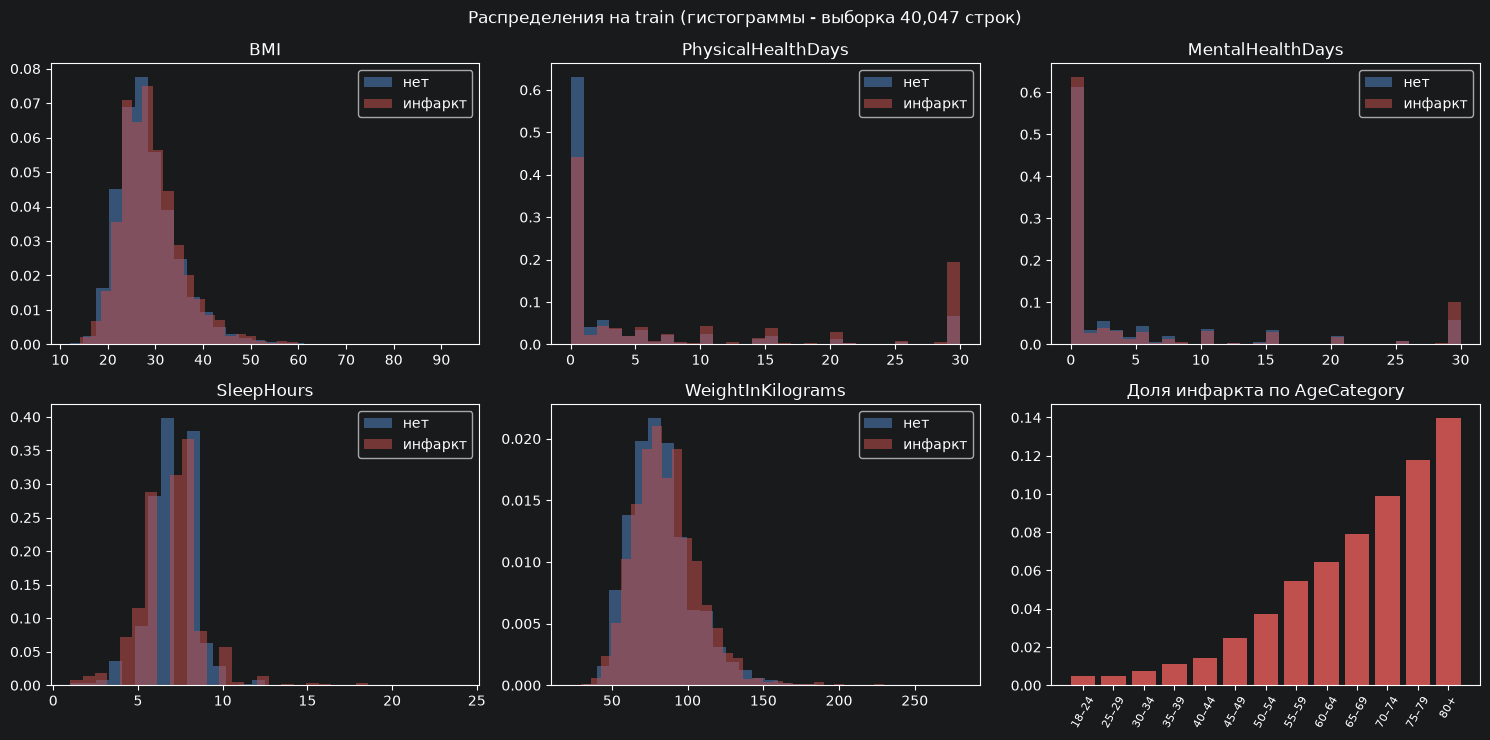

In [14]:
sample_pdf = pd.DataFrame(train_raw.select(NUMERIC + ["label"]).sample(fraction=0.15, seed=SEED).collect(),
                          columns=NUMERIC + ["label"])
age_t = cat_table[cat_table.feature == "AgeCategory"].dropna().sort_values("value")
age_t = age_t[age_t.value != "<null>"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, c in zip(axes.ravel()[:5], ["BMI", "PhysicalHealthDays", "MentalHealthDays", "SleepHours", "WeightInKilograms"]):
    for cls, col in [(0, "#4f81bd"), (1, "#c0504d")]:
        ax.hist(sample_pdf.loc[sample_pdf.label == cls, c].dropna(), bins=30, alpha=0.55, color=col,
                density=True, label="инфаркт" if cls else "нет")
    ax.set_title(c); ax.legend()
ax = axes.ravel()[5]
ax.bar(range(len(age_t)), age_t["rate"], color="#c0504d")
ax.set_xticks(range(len(age_t))); ax.set_xticklabels([v.replace("Age ", "").replace(" to ", "–").replace(" or older", "+")
                                                      for v in age_t.value], rotation=60, fontsize=8)
ax.set_title("Доля инфаркта по AgeCategory")
plt.suptitle(f"Распределения на train (гистограммы - выборка {len(sample_pdf):,} строк)")
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "distributions.png", dpi=120); plt.show()

**Вывод:**
- Возраст - самый сильный фактор. Доля инфаркта растёт плавно, от 0.5% в 18-24 года до 14.0% в 80+.
- Самочувствие (GeneralHealth): от 1.5% при «Excellent» до 21.5% при «Poor».
- Хронические болезни заметно повышают долю инфаркта. Среди перенёсших инсульт инфаркт был у 25.6% против 4.7% у остальных. Среди больных диабетом - 14.3% против 4.2%.
- Состояние зубов (RemovedTeeth, сколько зубов удалено) тоже сильно связано с целевой переменной: доля инфаркта в разных группах варьируется от 2.8% до 17.5%. Отчасти это связано с возрастом: с возрастом, как правило, уменьшается количество оставшихся зубов.
- HadAngina: 45.2% при «Yes» против 2.9 % при «No». Это подтверждает, что признак очень сильно связан с целевой переменной и по сути является другим сердечным диагнозом, поэтому его нужно исключить.
 - У ChestScan 10.4 % против 2.2 %. Пропуск тоже несёт информацию. Среди тех, кто не ответил про стенокардию, доля инфаркта 34.8 %, а среди не ответивших про инсульт - 18.7 %. Поэтому пропуски в категориях кодируются отдельной категорией Missing, а не удаляются.
- Числовые признаки (средние, без инфаркта / с инфарктом):
1. PhysicalHealthDays 4.0 против 9.3: на гистограмме у группы с инфарктом заметный пик на 30 днях;
2. MentalHealthDays 4.3 против 5.4;
3. BMI 28.5 против 29.3;
4. SleepHours 7.02 против 7.05, то есть сон почти не различается.

## 5. Выбор предикторов, целевая переменная и точки утечки

**Целевая переменная:** `HadHeartAttack` (Yes - 1). Опрос - срез: респондент отвечает, был ли у него инфаркт когда-либо,
и одновременно описывает текущее состояние. Поэтому часть признаков может быть следствием инфаркта, а не его причиной.

**Точки утечки и решения:**
1. **`HadAngina`** («врач говорил, что у вас стенокардия или ишемическая болезнь сердца») - по сути другой сердечный диагноз из того же вопроса о болезнях сердца.
   Для прогноза «по симптомам» это подсказка ответа - исключается из основной модели.
2. **`ChestScan`** («делали ли КТ грудной клетки») - обследование, которое обычно проводят после проблем с сердцем - исключается.
3. **Профилактика и обращения** (`PneumoVaxEver`, `FluVaxLast12`, `LastCheckupTime` и др.) - людям с болезнями сердца чаще рекомендуют прививки и осмотры,
   то есть связь может быть обратной. Признаки оставлены, их вклад проверяется абляцией.
4. **`State`** - не характеристика человека - не используется. **`HeightInMeters`, `WeightInKilograms`** дублируют `BMI` - не используются.
5. **`AgeCategory`** - упорядоченная категория - превращается в число (нижняя граница интервала, `age_num`).
6. **Пропуски** заполняются внутри `Pipeline` по статистикам train: медиана для чисел, отдельная категория `Missing` для строк.
7. **Порядок шагов:** разбиение до всех расчётов; веса классов - по train; порог - на valid; test - один раз.

In [15]:
LEAK = ["HadAngina", "ChestScan"]
DROP = ["State", "HeightInMeters", "WeightInKilograms", "AgeCategory"]   # AgeCategory → age_num
PREVENTIVE = ["LastCheckupTime", "FluVaxLast12", "PneumoVaxEver", "TetanusLast10Tdap", "HIVTesting", "HighRiskLastYear", "CovidPos"]
DEMO_LIFE_CAT = ["Sex", "RaceEthnicityCategory", "SmokerStatus", "ECigaretteUsage", "AlcoholDrinkers", "PhysicalActivities"]
DEMO_LIFE_NUM = ["age_num", "BMI", "SleepHours"]

BASE_CAT = [c for c in CATEGORICAL if c not in [TARGET] + LEAK + DROP]
BASE_NUM = ["age_num", "BMI", "SleepHours", "PhysicalHealthDays", "MentalHealthDays"]
FULL = dict(cats=BASE_CAT, nums=BASE_NUM)
print(f"Основной набор: {len(BASE_CAT)} категориальных + {len(BASE_NUM)} числовых")
print("Категориальные:", BASE_CAT)

# веса классов только по train: w_c = N / (K * N_c)
cnt = {int(r["label"]): r["count"] for r in split_df.filter("split = 'train'").groupBy("label").count().collect()}
n_train, K = sum(cnt.values()), len(cnt)
CLASS_WEIGHTS = {c: n_train / (K * n) for c, n in cnt.items()}
print("train по классам:", cnt, "| веса:", {c: round(w, 3) for c, w in CLASS_WEIGHTS.items()})

data = split_df.withColumn("class_weight", F.when(F.col("label") == 1.0, CLASS_WEIGHTS[1]).otherwise(CLASS_WEIGHTS[0]))
train = data.filter("split = 'train'").repartition(CORES).cache()
valid = data.filter("split = 'valid'").cache()
test  = data.filter("split = 'test'").cache()
print(f"train / valid / test: {train.count():,} / {valid.count():,} / {test.count():,} | партиций train: {train.rdd.getNumPartitions()}")

Основной набор: 29 категориальных + 5 числовых
Категориальные: ['Sex', 'GeneralHealth', 'LastCheckupTime', 'PhysicalActivities', 'RemovedTeeth', 'HadStroke', 'HadAsthma', 'HadSkinCancer', 'HadCOPD', 'HadDepressiveDisorder', 'HadKidneyDisease', 'HadArthritis', 'HadDiabetes', 'DeafOrHardOfHearing', 'BlindOrVisionDifficulty', 'DifficultyConcentrating', 'DifficultyWalking', 'DifficultyDressingBathing', 'DifficultyErrands', 'SmokerStatus', 'ECigaretteUsage', 'RaceEthnicityCategory', 'AlcoholDrinkers', 'HIVTesting', 'FluVaxLast12', 'PneumoVaxEver', 'TetanusLast10Tdap', 'HighRiskLastYear', 'CovidPos']
train по классам: {1: 15058, 0: 250451} | веса: {1: 8.816, 0: 0.53}
train / valid / test: 265,509 / 88,251 / 88,307 | партиций train: 20


**Вывод:** в основной набор вошли 34 признака: 29 категориальных и 5 числовых. Исключены HadAngina и ChestScan (утечка), State (не характеристика человека), рост и вес (они дублируют BMI). AgeCategory превращена в число age_num. Веса классов посчитаны только по train: 8.816 для положительного класса и 0.530 для отрицательного. Так 15058 случаев инфаркта весят при обучении столько же, сколько 250451 случай без него. Train перераспределён на 20 партиций, по одной на ядро, и закэширован.

## 6. Pipeline и модели

Вся предобработка входит в `Pipeline` и обучается только на train:

| Шаг                               | Что делает                                                                     |
|-----------------------------------|--------------------------------------------------------------------------------|
| `SQLTransformer`                  | `age_num` из `AgeCategory`; `NULL` в заменяется категориях на `Missing`        |
| `Imputer` (median)                | пропуски в числовых признаках на медиану в train                               |
| `StringIndexer` + `OneHotEncoder` | категории в индексы, затем one-hot (`handleInvalid="keep"` для новых значений) |
| `VectorAssembler`                 | собирает вектор признаков                                                      |
| `StandardScaler`                  | только для логистической регрессии                                             |
| классификатор                     | обучение с весами классов `class_weight`                                       |

Модели: логистическая регрессия, Random Forest и XGBoost (`SparkXGBClassifier`, обучение в `num_workers` параллельных задачах Spark).

In [16]:
def make_pipeline(kind, params, cats=FULL["cats"], nums=FULL["nums"]):
    fill = ", ".join(f"COALESCE({c}, 'Missing') AS {c}_f" for c in cats)
    prep = SQLTransformer(statement=
        "SELECT *, CAST(regexp_extract(AgeCategory, '([0-9]+)', 1) AS DOUBLE) AS age_num"
        + (", " + fill if fill else "") + " FROM __THIS__")
    imputer = Imputer(strategy="median", inputCols=nums, outputCols=[c + "_imp" for c in nums])
    stages = [prep, imputer]
    if cats:
        stages += [StringIndexer(inputCols=[c + "_f" for c in cats], outputCols=[c + "_idx" for c in cats],
                                 handleInvalid="keep", stringOrderType="alphabetAsc"),
                   OneHotEncoder(inputCols=[c + "_idx" for c in cats], outputCols=[c + "_ohe" for c in cats],
                                 dropLast=False, handleInvalid="keep")]
    stages.append(VectorAssembler(inputCols=[c + "_imp" for c in nums] + [c + "_ohe" for c in cats], outputCol="assembled"))

    if kind == "LogReg":
        stages += [StandardScaler(inputCol="assembled", outputCol="features", withMean=False, withStd=True),
                   LogisticRegression(featuresCol="features", labelCol="label", weightCol="class_weight",
                                      standardization=False, maxIter=100, **params)]
    elif kind == "RandomForest":
        stages.append(RandomForestClassifier(featuresCol="assembled", labelCol="label", weightCol="class_weight",
                                             featureSubsetStrategy="sqrt", seed=SEED, **params))
    elif kind == "XGBoost":
        stages.append(SparkXGBClassifier(features_col="assembled", label_col="label", weight_col="class_weight",
                                         num_workers=min(4, CORES), random_state=SEED, verbose=False, **params))

    return Pipeline(stages=stages)


def binary_scores(model, sdf):
    # score - вероятность класса 1
    # кэшируется, тк по одним оценкам считается несколько метрик
    return (model.transform(sdf)
                 .select("label", vector_to_array("probability")[1].alias("score"))
                 .cache())


EV = BinaryClassificationEvaluator(rawPredictionCol="score", labelCol="label")

def binary_metrics(scored, threshold=0.5):
    pred = (F.col("score") >= threshold).cast("int")
    y = F.col("label").cast("int")
    r = scored.select(F.sum(((pred == 1) & (y == 1)).cast("int")).alias("tp"),
                      F.sum(((pred == 1) & (y == 0)).cast("int")).alias("fp"),
                      F.sum(((pred == 0) & (y == 1)).cast("int")).alias("fn"),
                      F.sum(((pred == 0) & (y == 0)).cast("int")).alias("tn")).first()
    tp, fp, fn, tn = r["tp"], r["fp"], r["fn"], r["tn"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {"auc_pr": EV.setMetricName("areaUnderPR").evaluate(scored),
            "auc_roc": EV.setMetricName("areaUnderROC").evaluate(scored),
            "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
            "accuracy": (tp + tn) / (tp + fp + fn + tn),
            "specificity": tn / (tn + fp) if tn + fp else 0.0,
            "threshold": threshold, "tp": tp, "fp": fp, "fn": fn, "tn": tn}

def to_numpy(scored):
    rows = scored.select("label", "score").collect()
    return np.array([r[0] for r in rows]), np.array([r[1] for r in rows])

# проверка: конвейер собирается и обучается
_m = make_pipeline("LogReg", {"regParam": 0.01}).fit(train)
print([type(s).__name__ for s in _m.stages])

['SQLTransformer', 'ImputerModel', 'StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'StandardScalerModel', 'LogisticRegressionModel']


**Вывод:** конвейер из 7 стадий собирается и обучается: SQLTransformer - Imputer - StringIndexer - OneHotEncoder - VectorAssembler - StandardScaler - LogisticRegression. Все статистики предобработки (медианы, словари категорий) считаются внутри fit() только по train. Поэтому valid и test не влияют на обучение, а сохранённая модель применяет к новым данным ту же предобработку.

## 7. Baseline и подбор гиперпараметров на valid

**Baseline:**
- *мажоритарный класс* - всем ставим «нет инфаркта»: accuracy около 0.94, но не найден ни один больной (recall = 0) -
  поэтому при несбалансированных классах accuracy не годится как главная метрика;
- *правило по возрасту* - «риск», если 65 лет и старше;
- *правило по самочувствию* - «риск», если `GeneralHealth` = Fair или Poor;
- *правило по болезням* - «риск», если был инсульт или диабет.

**Подбор гиперпараметров.** Каждая комбинация обучается на train и оценивается на valid по **AUC-PR**: при 5 % положительных
AUC-ROC выглядит высоким даже у слабой модели, а AUC-PR показывает, насколько точно модель находит именно редкий класс.
Сетки небольшие, чтобы прогон занимал минуты, а не часы.

In [17]:
def rule_scores(sdf, expr):
    return sdf.select("label", F.expr(f"CAST(COALESCE({expr}, false) AS DOUBLE)").alias("score")).cache()

BASELINES = {
    "Baseline: всегда «нет»": "false",
    "Baseline: возраст ≥ 65": "CAST(regexp_extract(AgeCategory, '([0-9]+)', 1) AS INT) >= 65",
    "Baseline: GeneralHealth Fair/Poor": "GeneralHealth IN ('Fair', 'Poor')",
    "Baseline: инсульт или диабет": "HadStroke = 'Yes' OR HadDiabetes = 'Yes'",
}
base_valid = pd.DataFrame([{"model": name, **binary_metrics(rule_scores(valid, e), 0.5)} for name, e in BASELINES.items()])
base_valid[["model", "auc_pr", "auc_roc", "precision", "recall", "f1", "accuracy"]].round(3)

,model,auc_pr,auc_roc,precision,recall,f1,accuracy
0,Baseline: всегда «нет»,0.058,0.500,0.000,0.000,0.000,0.942
1,Baseline: возраст ≥ 65,0.099,0.663,0.108,0.666,0.185,0.661
2,Baseline: GeneralHealth Fair/Poor,0.123,0.646,0.148,0.452,0.223,0.817
3,Baseline: инсульт или диабет,0.134,0.658,0.162,0.464,0.240,0.830


In [18]:
GRIDS = {
    "LogReg": [{"regParam": r, "elasticNetParam": a} for r, a in [(0.001, 0.0), (0.01, 0.0), (0.1, 0.0), (0.01, 0.5)]],
    "RandomForest": [{"numTrees": t, "maxDepth": d, "minInstancesPerNode": 50, "subsamplingRate": 0.7}
                     for t, d in [(100, 6), (100, 10), (200, 12)]],
    "XGBoost" : [{"n_estimators": n, "max_depth": d, "learning_rate": 0.1,
                     "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 5}
                    for n, d in [(200, 4), (400, 4), (300, 6)]]
}


tuning, best = [], {}
t_all = time.perf_counter()
for kind, grid in GRIDS.items():
    for params in grid:
        t0 = time.perf_counter()
        model = make_pipeline(kind, params).fit(train)
        fit_s = time.perf_counter() - t0
        sc = binary_scores(model, valid)
        m = binary_metrics(sc, 0.5)
        tuning.append({"model": kind, "params": json.dumps(params), "fit_s": round(fit_s, 1),
                       "auc_pr": m["auc_pr"], "auc_roc": m["auc_roc"], "f1@0.5": m["f1"]})
        print(f"  {kind:13s} {params}  fit {fit_s:5.1f} с  AUC-PR={m['auc_pr']:.4f}")
        if kind not in best or m["auc_pr"] > best[kind]["auc_pr"]:
            if kind in best:
                best[kind]["valid_scores"].unpersist()
            best[kind] = {"params": params, "model": model, "valid_scores": sc, "auc_pr": m["auc_pr"]}
        else:
            sc.unpersist()
print(f"Подбор занял {(time.perf_counter() - t_all) / 60:.1f} мин")

tuning_df = pd.DataFrame(tuning).sort_values(["model", "auc_pr"], ascending=[True, False])
tuning_df.round(4)

  LogReg        {'regParam': 0.001, 'elasticNetParam': 0.0}  fit  17.8 с  AUC-PR=0.2579
  LogReg        {'regParam': 0.01, 'elasticNetParam': 0.0}  fit  12.6 с  AUC-PR=0.2578
  LogReg        {'regParam': 0.1, 'elasticNetParam': 0.0}  fit  15.0 с  AUC-PR=0.2540
  LogReg        {'regParam': 0.01, 'elasticNetParam': 0.5}  fit  14.4 с  AUC-PR=0.2591
  RandomForest  {'numTrees': 100, 'maxDepth': 6, 'minInstancesPerNode': 50, 'subsamplingRate': 0.7}  fit  14.5 с  AUC-PR=0.2366
  RandomForest  {'numTrees': 100, 'maxDepth': 10, 'minInstancesPerNode': 50, 'subsamplingRate': 0.7}  fit  34.6 с  AUC-PR=0.2501
  RandomForest  {'numTrees': 200, 'maxDepth': 12, 'minInstancesPerNode': 50, 'subsamplingRate': 0.7}  fit  99.8 с  AUC-PR=0.2540
  XGBoost       {'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 5}  fit  20.4 с  AUC-PR=0.2621
  XGBoost       {'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.8, 'c

,model,params,fit_s,auc_pr,auc_roc,f1@0.5
3,LogReg,"{""regParam"": 0.01, ""elasticNetParam"": 0.5}",14.4,0.2591,0.8374,0.2629
0,LogReg,"{""regParam"": 0.001, ""elasticNetParam"": 0.0}",17.8,0.2579,0.8378,0.2629
1,LogReg,"{""regParam"": 0.01, ""elasticNetParam"": 0.0}",12.6,0.2578,0.8379,0.2646
2,LogReg,"{""regParam"": 0.1, ""elasticNetParam"": 0.0}",15.0,0.2540,0.8352,0.2659
6,RandomForest,"{""numTrees"": 200, ""maxDepth"": 12, ""minInstance...",99.8,0.2540,0.8348,0.2614
5,RandomForest,"{""numTrees"": 100, ""maxDepth"": 10, ""minInstance...",34.6,0.2501,0.8320,0.2558
4,RandomForest,"{""numTrees"": 100, ""maxDepth"": 6, ""minInstances...",14.5,0.2366,0.8221,0.2440
7,XGBoost,"{""n_estimators"": 200, ""max_depth"": 4, ""learnin...",20.4,0.2621,0.8402,0.2599
8,XGBoost,"{""n_estimators"": 400, ""max_depth"": 4, ""learnin...",19.7,0.2596,0.8392,0.2618
9,XGBoost,"{""n_estimators"": 300, ""max_depth"": 6, ""learnin...",19.4,0.2494,0.8340,0.2672


In [19]:
valid_rows = [{"model": kind, "params": json.dumps(b["params"]), **binary_metrics(b["valid_scores"], 0.5)}
              for kind, b in best.items()]
compare_valid = pd.concat([pd.DataFrame(valid_rows), base_valid.assign(params="—")], ignore_index=True)
compare_valid = compare_valid.sort_values("auc_pr", ascending=False)

BEST_KIND = compare_valid[compare_valid.model.isin(best.keys())].iloc[0]["model"]
BEST = best[BEST_KIND]
print("Лучший метод на valid по AUC-PR:", BEST_KIND, BEST["params"])
compare_valid[["model", "auc_pr", "auc_roc", "precision", "recall", "f1", "accuracy", "params"]].round(3)

Лучший метод на valid по AUC-PR: XGBoost {'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 5}


,model,auc_pr,auc_roc,precision,recall,f1,accuracy,params
2,XGBoost,0.262,0.840,0.156,0.789,0.260,0.740,"{""n_estimators"": 200, ""max_depth"": 4, ""learnin..."
0,LogReg,0.259,0.837,0.159,0.761,0.263,0.753,"{""regParam"": 0.01, ""elasticNetParam"": 0.5}"
1,RandomForest,0.254,0.835,0.157,0.770,0.261,0.748,"{""numTrees"": 200, ""maxDepth"": 12, ""minInstance..."
6,Baseline: инсульт или диабет,0.134,0.658,0.162,0.464,0.240,0.830,—
5,Baseline: GeneralHealth Fair/Poor,0.123,0.646,0.148,0.452,0.223,0.817,—
4,Baseline: возраст ≥ 65,0.099,0.663,0.108,0.666,0.185,0.661,—
3,Baseline: всегда «нет»,0.058,0.500,0.000,0.000,0.000,0.942,—


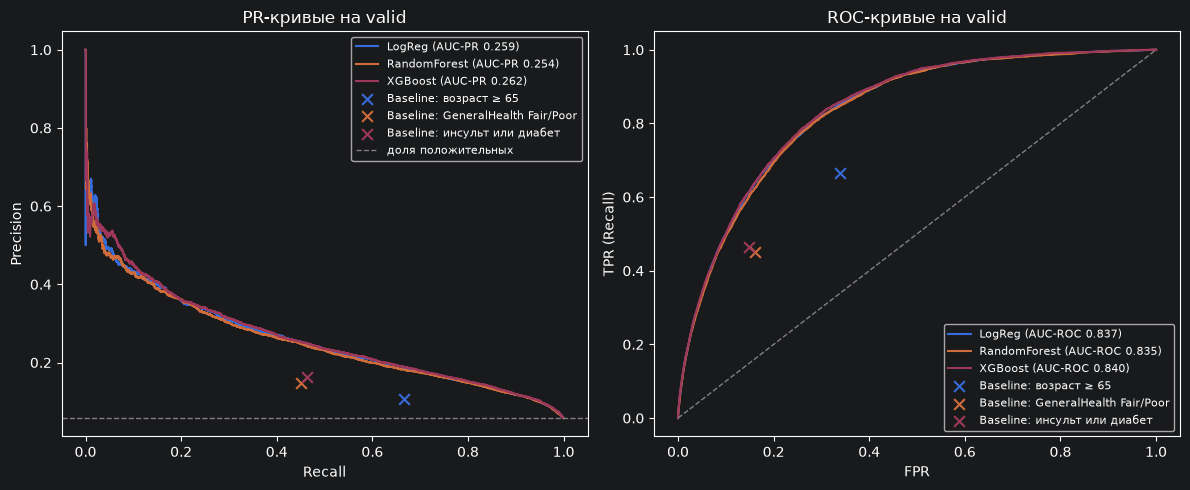

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for kind, b in best.items():
    yv, sv = to_numpy(b["valid_scores"])
    p, r, _ = precision_recall_curve(yv, sv); fpr, tpr, _ = roc_curve(yv, sv)
    m = compare_valid.set_index("model").loc[kind]
    ax1.plot(r, p, label=f"{kind} (AUC-PR {m.auc_pr:.3f})")
    ax2.plot(fpr, tpr, label=f"{kind} (AUC-ROC {m.auc_roc:.3f})")
for _, b in base_valid.iloc[1:].iterrows():
    ax1.scatter(b.recall, b.precision, marker="x", s=60, label=b.model)
    ax2.scatter(1 - b.specificity, b.recall, marker="x", s=60, label=b.model)
ax1.axhline(yv.mean(), ls="--", c="grey", lw=1, label="доля положительных")
ax2.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
ax1.set(xlabel="Recall", ylabel="Precision", title="PR-кривые на valid")
ax2.set(xlabel="FPR", ylabel="TPR (Recall)", title="ROC-кривые на valid")
ax1.legend(fontsize=8); ax2.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "valid_curves.png", dpi=120); plt.show()

**Вывод:**
- Baseline. Правило «всегда нет» даёт accuracy 0.942, но recall 0: не найден ни один случай инфаркта. Простые правила дают AUC-PR 0.099–0.134. Лучшее из них - «инсульт или диабет»: F1 0.240.
- Подбор занял 5.9 мин, обучено 10 конфигураций:
1. Логистическая регрессия. Все 4 варианта почти одинаковы: AUC-PR 0.254–0.259. На 265 тыс. строк регуляризация почти не влияет.
2. Random Forest. Чем глубже деревья, тем лучше: 0.237 - 0.250 - 0.254. Но самый глубокий вариант обучался 100 с.
3. XGBoost. Лучший вариант - 200 деревьев глубины 4: AUC-PR 0.262. 400 деревьев дали 0.260, а глубина 6 - 0.249. Это начало переобучения.
- Сравнение моделей на valid. XGBoost 0.262, LogReg 0.259, RF 0.254. AUC-ROC 0.840 / 0.837 / 0.835. Разница всего 0.003–0.008: PR- и ROC-кривые трёх моделей почти совпадают. Выбран XGBoost, но логистическая регрессия почти не уступает ему, учится за 11–18 с и легко интерпретируется.
Все модели лучше baseline: AUC-PR у них примерно в 2 раза выше, чем у лучшего правила (0.134), и в 4.5 раза выше доли больных (0.058).

## 8. Выбор порога на valid

Из-за весов классов вероятности модели смещены вверх, и порог 0.5 не оптимален. Порог выбирается на valid. Модель используется как скрининг, где пропуск человека из группы риска дороже лишнего обследования, поэтому выбран порог, при котором recall на valid не ниже 0.80. Для сравнения показан порог с максимумом F1 (баланс precision и recall).

In [21]:
yv, sv = to_numpy(BEST["valid_scores"])
prec, rec, thr = precision_recall_curve(yv, sv)
f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
BALANCED = float(thr[int(np.argmax(f1))])
i_rec = np.where(rec[:-1] >= 0.80)[0]
THR_RECALL80 = float(thr[i_rec[-1]]) if len(i_rec) else float(thr[0])
THRESHOLD = THR_RECALL80

thr_table = pd.DataFrame([
    {"порог": "0.5 (по умолчанию)", **binary_metrics(BEST["valid_scores"], 0.5)},
    {"порог": "max F1 на valid (баланс метрик)", **binary_metrics(BEST["valid_scores"], BALANCED)},
    {"порог": "recall ≥ 0.80 (выбран)", **binary_metrics(BEST["valid_scores"], THR_RECALL80)},
])
print(f"{BEST_KIND}: выбранный порог = {THRESHOLD:.4f}")
thr_table[["порог", "threshold", "precision", "recall", "f1", "accuracy", "specificity", "tp", "fp", "fn", "tn"]].round(3)

XGBoost: выбранный порог = 0.4857


,порог,threshold,precision,recall,f1,accuracy,specificity,tp,fp,fn,tn
0,0.5 (по умолчанию),0.500,0.156,0.789,0.260,0.740,0.737,4031,21885,1078,61257
1,max F1 на valid (баланс метрик),0.758,0.256,0.445,0.325,0.893,0.920,2271,6616,2838,76526
2,recall ≥ 0.80 (выбран),0.486,0.152,0.800,0.256,0.730,0.726,4088,22796,1021,60346


**Вывод:**
- Из-за весов классов при пороге 0.5 модель слишком часто говорит «да»: recall 0.789, но precision 0.156 и 21885 ложных срабатываний.
- Порог с максимумом F1 на valid равен 0.758: precision 0.256, F1 0.325, но recall всего 0.445 - пропускается больше половины больных (2838 из 5109).
- Модель используется как скрининг: человеку из группы риска предлагают дообследование, и пропуск больного здесь дороже лишнего обследования. Поэтому **выбран порог 0.486, при котором recall на valid не ниже 0.80**: найдено 4088 больных из 5109, precision 0.152, F1 0.256.
- По сравнению с порогом по F1 это на 1817 найденных больных больше, но ложных срабатываний 22796 вместо 6616 (в 3.4 раза больше). Ложное срабатывание - это лишнее обследование, пропуск - человек, не получивший помощь.

## 9. Однократная оценка на test

Метод, гиперпараметры и порог выбраны на train и valid. Теперь выбранная модель один раз оценивается на test;
для сравнения на test посчитаны необучаемые baseline-правила.

In [22]:
test_scores = binary_scores(BEST["model"], test)
test_rows = [{"model": f"{BEST_KIND} (порог {THRESHOLD:.3f})", **binary_metrics(test_scores, THRESHOLD)}]
test_rows += [{"model": name, **binary_metrics(rule_scores(test, e), 0.5)} for name, e in BASELINES.items()]
test_table = pd.DataFrame(test_rows)
test_table[["model", "auc_pr", "auc_roc", "precision", "recall", "f1", "accuracy", "specificity", "tp", "fp", "fn", "tn"]].round(3)

,model,auc_pr,auc_roc,precision,recall,f1,accuracy,specificity,tp,fp,fn,tn
0,XGBoost (порог 0.486),0.262,0.839,0.148,0.797,0.250,0.732,0.728,3940,22676,1001,60690
1,Baseline: всегда «нет»,0.056,0.500,0.000,0.000,0.000,0.944,1.000,0,0,4941,83366
2,Baseline: возраст ≥ 65,0.095,0.660,0.104,0.659,0.179,0.662,0.662,3254,28162,1687,55204
3,Baseline: GeneralHealth Fair/Poor,0.119,0.645,0.142,0.452,0.217,0.817,0.839,2234,13452,2707,69914
4,Baseline: инсульт или диабет,0.127,0.652,0.154,0.450,0.229,0.831,0.853,2225,12238,2716,71128


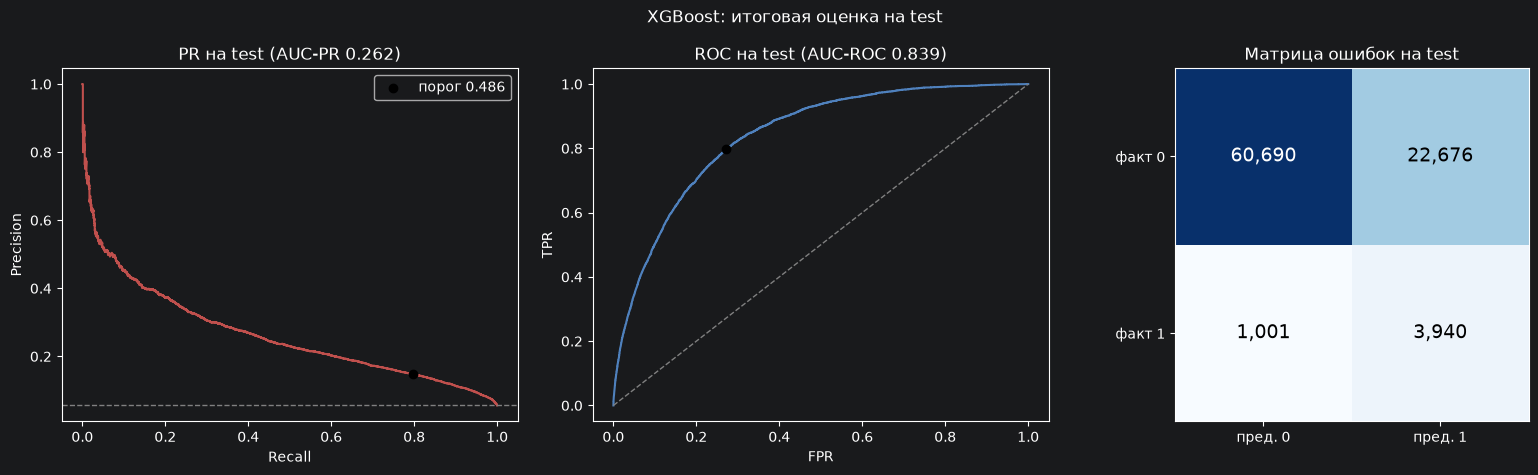

In [23]:
mt = test_rows[0]
yt, st_ = to_numpy(test_scores)
p, r, _ = precision_recall_curve(yt, st_); fpr, tpr, _ = roc_curve(yt, st_)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].plot(r, p, c="#c0504d"); axes[0].axhline(yt.mean(), ls="--", c="grey", lw=1)
axes[0].scatter(mt["recall"], mt["precision"], c="k", zorder=3, label=f"порог {THRESHOLD:.3f}")
axes[0].set(xlabel="Recall", ylabel="Precision", title=f"PR на test (AUC-PR {mt['auc_pr']:.3f})"); axes[0].legend()
axes[1].plot(fpr, tpr, c="#4f81bd"); axes[1].plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
axes[1].scatter(1 - mt["specificity"], mt["recall"], c="k", zorder=3)
axes[1].set(xlabel="FPR", ylabel="TPR", title=f"ROC на test (AUC-ROC {mt['auc_roc']:.3f})")
cm = np.array([[mt["tn"], mt["fp"]], [mt["fn"], mt["tp"]]])
axes[2].imshow(cm, cmap="Blues")
for (a, b), v in np.ndenumerate(cm):
    axes[2].text(b, a, f"{v:,}", ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else "black")
axes[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["пред. 0", "пред. 1"], yticklabels=["факт 0", "факт 1"],
            title="Матрица ошибок на test")
plt.suptitle(f"{BEST_KIND}: итоговая оценка на test")
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "test_eval.png", dpi=120); plt.show()

**Вывод:**
- XGBoost с порогом 0.486 на test: AUC-PR 0.262, AUC-ROC 0.839, recall 0.797, precision 0.148, F1 0.250. На valid было 0.262 / 0.840 / 0.800 / 0.152 / 0.256 - метрики совпали. Модель и порог не подогнаны под valid: требование «recall не ниже 0.80» на новых данных почти выполняется (0.797).
- Матрица ошибок: из 4941 случая инфаркта найдено 3940, пропущено 1001. Модель отметила 26616 человек, и у 14.8 % из них (примерно каждого седьмого) действительно был инфаркт. Без модели это был бы каждый восемнадцатый (5.6 %), то есть группа риска в 2.6 раза «плотнее» случайной выборки.
- Сравнение с правилом «возраст ≥ 65», у которого похожий высокий recall: правило находит 3254 больных при 28162 ложных срабатываниях, а модель - на 686 больных больше при 5486 ложных срабатываниях меньше.
- У остальных baseline-правил F1 на test 0.179–0.229, recall не выше 0.659. Правило «всегда нет» имеет accuracy 0.944 - выше, чем у модели (0.732), - но не находит ни одного случая, поэтому accuracy в этой задаче не показательна.

## 10. Важность признаков и абляция

Важность: Random Forest - `featureImportances`, XGBoost - `gain`, логистическая регрессия - коэффициенты на стандартизированных признаках
(знак показывает направление: «+» повышает риск). Имена признаков берутся из метаданных вектора после `VectorAssembler`.

**Абляция** - лучший метод с теми же гиперпараметрами на других наборах признаков (оценка на valid):
- основной набор;
- основной + `HadAngina`, `ChestScan` - насколько вырастет качество от признаков-«подсказок» (размер утечки);
- без признаков обращений в медицину;
- только демография и образ жизни.

In [24]:
def feature_names(model, sdf):
    meta = model.transform(sdf.limit(1)).schema["assembled"].metadata["ml_attr"]["attrs"]
    attrs = sorted([a for group in meta.values() for a in group], key=lambda a: a["idx"])
    return [a["name"].replace("_imp", "").replace("_f_ohe", "").replace("_ohe", "") for a in attrs]

names = feature_names(best["RandomForest"]["model"], train)
imp = pd.DataFrame({"feature": names})
imp["RandomForest"] = best["RandomForest"]["model"].stages[-1].featureImportances.toArray()
lr = best["LogReg"]["model"].stages[-1]
imp["LogReg coef"] = lr.coefficients.toArray()
imp["LogReg |coef|"] = imp["LogReg coef"].abs()
gain = best["XGBoost"]["model"].stages[-1].get_feature_importances(importance_type="gain")
g = np.array([gain.get(f"f{i}", 0.0) for i in range(len(names))])
imp["XGBoost gain"] = g / g.sum() if g.sum() else g

imp = imp.sort_values(imp.columns[-1], ascending=False).reset_index(drop=True)
imp.head(15).round(3)

,feature,RandomForest,LogReg coef,LogReg |coef|,XGBoost gain
0,DifficultyWalking_Yes,0.047,0.050,0.050,0.108
1,Sex_Male,0.031,0.194,0.194,0.071
2,RemovedTeeth_None of them,0.062,-0.107,0.107,0.065
3,age_num,0.155,0.719,0.719,0.058
4,HadStroke_No,0.049,-0.168,0.168,0.056
5,HadDiabetes_Yes,0.046,0.111,0.111,0.048
6,GeneralHealth_Very good,0.019,-0.180,0.180,0.045
7,HadCOPD_No,0.029,-0.071,0.071,0.036
8,GeneralHealth_Excellent,0.020,-0.242,0.242,0.031
9,HadArthritis_No,0.034,-0.041,0.041,0.029


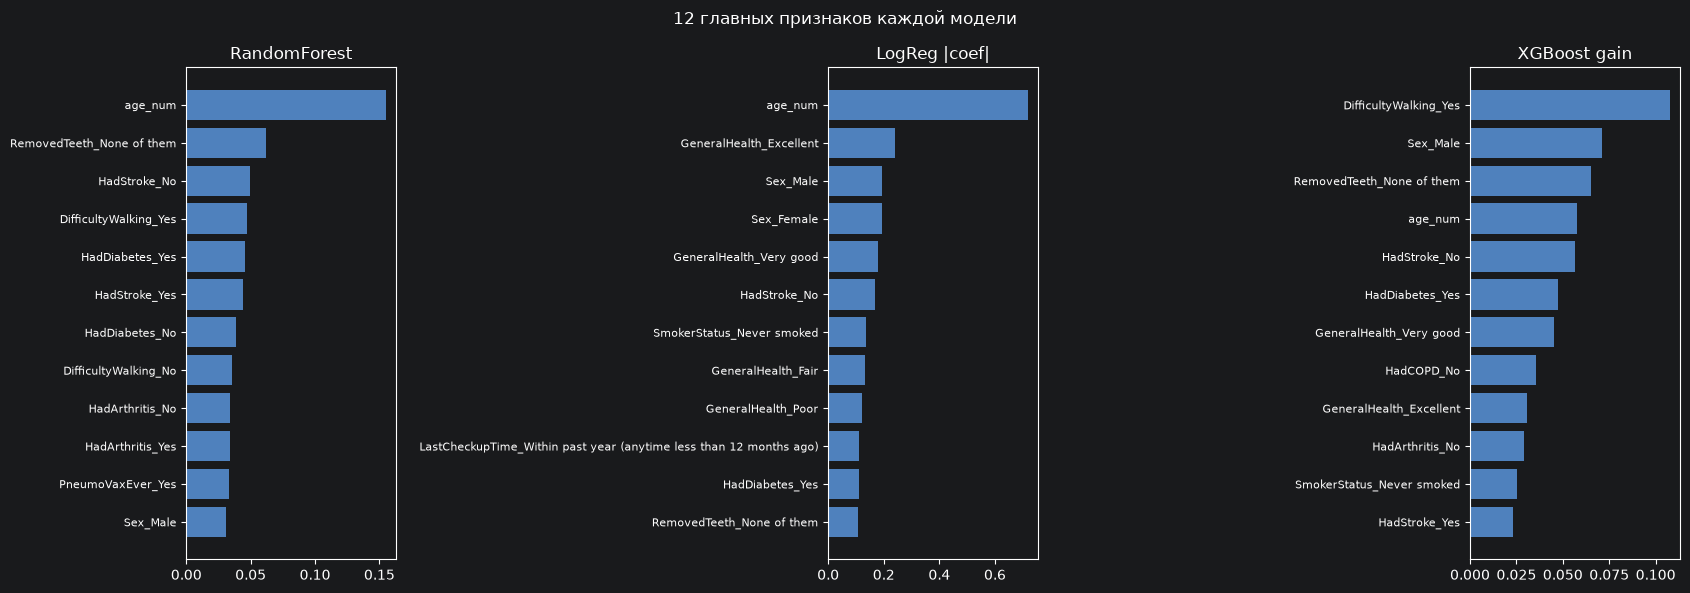

In [25]:
cols = ["RandomForest", "LogReg |coef|", imp.columns[-1]]
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, c in zip(axes, cols):
    top = imp.sort_values(c, ascending=False).head(12).iloc[::-1]
    ax.barh(top["feature"], top[c], color="#4f81bd"); ax.set_title(c); ax.tick_params(axis="y", labelsize=8)
plt.suptitle("12 главных признаков каждой модели")
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "feature_importance.png", dpi=120); plt.show()

In [26]:
ABLATION = {
    "основной набор": FULL,
    "+ HadAngina, ChestScan (утечка)": dict(cats=BASE_CAT + LEAK, nums=BASE_NUM),
    "без обращений в медицину": dict(cats=[c for c in BASE_CAT if c not in PREVENTIVE], nums=BASE_NUM),
    "только демография и образ жизни": dict(cats=DEMO_LIFE_CAT, nums=DEMO_LIFE_NUM),
}
abl = []
for name, fs in ABLATION.items():
    t0 = time.perf_counter()
    m_ = make_pipeline(BEST_KIND, BEST["params"], **fs).fit(train)
    sc = binary_scores(m_, valid)
    met = binary_metrics(sc, 0.5); sc.unpersist()
    abl.append({"набор признаков": name, "признаков": len(fs["cats"]) + len(fs["nums"]),
                "auc_pr": met["auc_pr"], "auc_roc": met["auc_roc"], "fit_s": round(time.perf_counter() - t0, 1)})
ablation_df = pd.DataFrame(abl)
ablation_df["дельта auc_pr"] = ablation_df["auc_pr"] - ablation_df.loc[0, "auc_pr"]
print("Метод:", BEST_KIND, BEST["params"], "| оценка на valid")
ablation_df.round(4)

Метод: XGBoost {'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 5} | оценка на valid


,набор признаков,признаков,auc_pr,auc_roc,fit_s,дельта auc_pr
0,основной набор,34,0.2621,0.8402,36.8,0.0000
1,"+ HadAngina, ChestScan (утечка)",36,0.4316,0.8928,36.2,0.1695
2,без обращений в медицину,27,0.2638,0.8396,33.6,0.0017
3,только демография и образ жизни,9,0.1760,0.7875,30.4,-0.0861


**Вывод:**
- **Возраст** - главный признак у Random Forest (важность 0.155) и у логистической регрессии (коэффициент +0.719, самый большой по модулю).
- У XGBoost на первом месте «трудности при ходьбе» (DifficultyWalking_Yes, gain 0.108), дальше мужской пол (0.071), отсутствие удалённых зубов (0.065) и возраст (0.058).
- Во всех трёх моделях в верхней части списка одни и те же признаки: возраст, пол, инсульт, диабет, общее самочувствие, трудности при ходьбе, состояние зубов, курение.
- Знаки коэффициентов логистической регрессии согласуются с медицинскими представлениями: мужской пол +0.194, диабет +0.111, отличное самочувствие −0.242, «никогда не курил» −0.138, отсутствие инсульта −0.168.
- One-hot кодирование разбивает признак на пары (HadStroke_Yes и HadStroke_No), поэтому важность одного признака делится между двумя столбцами.
- **Абляция** (XGBoost, valid):
1. Добавление HadAngina и ChestScan поднимает AUC-PR с 0.262 до 0.432 , AUC-ROC - с 0.840 до 0.893. Такой прирост дают не симптомы, а другой сердечный диагноз и обследование, которое обычно делают после болезни. Это подтверждает, что признаки правильно исключены как утечка.
2. Без признаков обращений за медицинскими услугами (прививки, осмотры, тесты) AUC-PR 0.264: эти 7 признаков ничего не добавляют, и их можно убрать, чтобы упростить модель.
3. Только демография и образ жизни (9 признаков): AUC-PR 0.176. Самочувствие и хронические болезни дают примерно треть качества, но даже на 9 простых признаках модель лучше любого baseline-правила (0.134).

## 11. Сохранение модели и результатов

Сохраняется весь `PipelineModel` (предобработка + модель): при применении к новым данным заполнение пропусков и кодирование категорий
выполнятся так же, как при обучении. Рядом - JSON с конфигурацией, таблицы метрик и рисунки.
После сохранения модель загружается обратно, и её метрики на test сравниваются с исходными.

In [27]:
MODEL_DIR = RESULTS / "best_model"
BEST["model"].write().overwrite().save(str(MODEL_DIR))

config = {
    "task": "HadHeartAttack binary classification",
    "dataset": "kamilpytlak/personal-key-indicators-of-heart-disease (2022, with NaNs)",
    "seed": SEED, "split": "60/20/20 by sha2(all columns|seed)",
    "model": BEST_KIND, "params": BEST["params"], "threshold": THRESHOLD,
    "class_weights": CLASS_WEIGHTS, "features": FULL, "excluded_leakage": LEAK,
    "valid_auc_pr": float(compare_valid.set_index("model").loc[BEST_KIND, "auc_pr"]),
    "test_metrics": {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in test_rows[0].items() if k != "model"},
    "spark": spark.version, "xgboost": xgboost.__version__,
}
(RESULTS / "model_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
tuning_df.to_csv(RESULTS / "tuning_valid.csv", index=False)
compare_valid.to_csv(RESULTS / "compare_valid.csv", index=False)
test_table.to_csv(RESULTS / "test_metrics.csv", index=False)
ablation_df.to_csv(RESULTS / "ablation_valid.csv", index=False)
imp.to_csv(RESULTS / "feature_importance.csv", index=False)

loaded = PipelineModel.load(str(MODEL_DIR))
m_loaded = binary_metrics(binary_scores(loaded, test), THRESHOLD)
print("AUC-PR на test: исходная модель {:.6f} | загруженная {:.6f}".format(mt["auc_pr"], m_loaded["auc_pr"]))
print("TP/FP/FN/TN совпадают:", all(m_loaded[k] == mt[k] for k in ("tp", "fp", "fn", "tn")))
print("Сохранено:", sorted(str(p.relative_to(RESULTS)) for p in RESULTS.rglob("*") if p.is_file() and "best_model" not in p.parts))

AUC-PR на test: исходная модель 0.262306 | загруженная 0.262322
TP/FP/FN/TN совпадают: True
Сохранено: ['ablation_valid.csv', 'compare_valid.csv', 'feature_importance.csv', 'figures\\distributions.png', 'figures\\feature_importance.png', 'figures\\test_eval.png', 'figures\\valid_curves.png', 'model_config.json', 'test_metrics.csv', 'tuning_valid.csv']


**Вывод:**
- Весь PipelineModel (предобработка + XGBoost) сохранён в results_pr5/best_model. Рядом лежат model_config.json (seed, модель, гиперпараметры, порог 0.486, веса классов, метрики на test, версии Spark и XGBoost), 5 таблиц CSV и 4 рисунка.
- Загруженная модель дала на test точно такую же матрицу ошибок (TP/FP/FN/TN совпали). AUC-PR 0.262306 против 0.262322 - расхождение в пятом знаке; это погрешность вычисления площади, на прогнозы оно не влияет.

## 12. Итоговые выводы и ограничения

**Выводы:**
1. **Данные.** Опрос CDC BRFSS 2022: 445132 строки, 133 МБ. Spark читает его в 20 партиций, и все шаги - проверки качества, разбиение, обучение - выполняются параллельно. Классы сильно несбалансированы: инфаркт перенесли 5.64 %. Пропуски есть в 38 столбцах из 40 (до 18.5 %) и заполняются внутри Pipeline по статистикам train.
2. **Разбиение.** Хеш-разбиение 60 / 20 / 20 воспроизводимо и не зависит от числа партиций; доля положительного класса во всех частях одинакова (5.60–5.79 %). Утечки исключены (стенокардия, КТ грудной клетки), веса классов посчитаны по train, порог выбран на valid, test использован один раз.
3. **Модели.** На valid все три метода близки: AUC-PR XGBoost 0.262, LogReg 0.259, RF 0.254. Все примерно в 2 раза лучше простых правил (0.134) и в 4.5 раза выше доли больных. Выбран XGBoost (200 деревьев глубины 4); логистическая регрессия почти не уступает и при этом быстрее и проще в интерпретации.
4. **Порог и test.** Для скрининга выбран порог 0.486 (recall на valid не ниже 0.80). На test модель нашла 3940 из 4941 случая инфаркта (recall 0.797) при precision 0.148: каждый седьмой отмеченный действительно перенёс инфаркт, без модели - каждый восемнадцатый. Метрики test совпали с valid. Порог с максимумом F1 (0.758) дал бы меньше ложных срабатываний, но находил бы лишь 44.5 % больных: выбор порога зависит от цели применения, а не только от метрики.
5. **Признаки.** Главные факторы - возраст, общее самочувствие, трудности при ходьбе, инсульт, диабет, пол, состояние зубов. Утечка заметно завышает качество: с HadAngina и ChestScan AUC-PR 0.432 вместо 0.262. Признаки обращений в медицину ничего не добавляют.

**Ограничения:**
1. Опрос - срез одного года: модель находит связи признаков с перенесённым инфарктом, но не предсказывает будущий инфаркт;
   часть признаков (самочувствие, курение, обращения к врачу) могла измениться *после* заболевания.
2. Ответы самоотчётные (со слов респондента), без медицинских измерений.
3. Подбор гиперпараметров — на одном valid по небольшой сетке, без кросс-валидации.
4. Модель не заменяет диагноз врача.

In [28]:
spark.catalog.clearCache()
spark.stop()